<a href="https://colab.research.google.com/github/sancarg/Machine_Learning/blob/master/Fraud_Detection/fraud_detection_EDA_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WELLCOME

Welcome to "***Fraud Detection Project***".

One of the challenges in this project is the absence of domain knowledge. So without knowing what the column names are, you will only be interested in their values. The other one is the class frequencies of the target variable are quite imbalanced.

You will implement ***Logistic Regression, Random Forest, XGBoost,and Neural Network*** algorithms and ***Unbalanced Data Techniques*** . Also visualize performances of the models using ***Seaborn, Matplotlib*** and ***Yellowbrick*** in a variety of ways.

Data drift and model drirft are key consepts about ML and MLOPS, you can monitor and check your data and models with plenty of ways and tools. ***Deepchecks*** is one of them and the leading tool for testing and for validating your machine learning models and data, and it enables doing so with minimal effort. In this project, you will apply ***Data Integrity, Train-Test Validation, and Model Evaluation*** checks.
Deepchecks Intruduction : https://youtu.be/7ELdizoi6BU

Before diving into the project, please take a look at the Determines and Tasks.

- ***NOTE:*** *This tutorial assumes that you already know the basics of coding in Python and are familiar with model deployement (Streamlit) as well as the theory behind algorithms*


# Determines
The datasets contains transactions made by credit cards in September 2013 by european cardholders. This dataset presents transactions that occurred in two days, where it has **492 frauds** out of **284,807** transactions. The dataset is **highly unbalanced**, the positive class (frauds) account for 0.172% of all transactions.

**Feature Information:**

**Time**: This feature is contains the seconds elapsed between each transaction and the first transaction in the dataset.

**Amount**:  This feature is the transaction Amount, can be used for example-dependant cost-senstive learning.

**Class**: This feature is the target variable and it takes value 1 in case of fraud and 0 otherwise.

---

The aim of this project is to predict whether a credit card transaction is fraudulent. Of course, this is not easy to do.
First of all, you need to analyze and recognize your data well in order to draw your roadmap and choose the correct arguments you will use. Accordingly, you can examine the frequency distributions of variables. You can observe variable correlations and want to explore multicollinearity. You can display the distribution of the target variable's classes over other variables.
Also, it is useful to take missing values and outliers.

After these procedures, you can move on to the model building stage by doing the basic data pre-processing you are familiar with.

Start with Logistic Regression and evaluate model performance. You will apply the Unbalanced Data Techniques used to increase the performance. Next, observe their effects.

Then, you will use four different algorithms in the model building phase.


# Tasks

#### 1. Exploratory Data Analysis & Data Cleaning

- Import Modules, Load Data & Data Review
- Apply Data Integrity Checks
- Exploratory Data Analysis
- Data Cleaning
    
#### 2. Data Preprocessing

- Train - Test Split
- Train - Test Split Validation Checks
- Scaling

#### 3. Model Building

- Logistic Regression
- Random Forest Classifier
- XGBoost Classifier
- Neural Network

#### 4. Model Evaluation

#### 5. Deployment With Streamlit

# Exploratory Data Analysis & Data Cleaning

### Import Modules, Load Data & Data Review

In [ ]:
pip install shap

In [ ]:
pip install scikeras

In [ ]:
pip install imbalanced-learn==0.12.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.3/258.3 kB 21.9 MB/s eta 0:00:00
  Attempting uninstall: imbalanced-learn
    Found existing installation: imbalanced-learn 0.14.2
    Uninstalling imbalanced-learn-0.14.2:
      Successfully uninstalled imbalanced-learn-0.14.2


In [ ]:
pip install deepchecks

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 53.7 MB/s eta 0:00:00


In [ ]:
# main libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import plotly
import plotly.express as px
import plotly.figure_factory as ff
import shap

#To display the plots
# %matplotlib inline

# Figure&Display options
plt.rcParams["figure.figsize"] = (10,6)
sns.set_style("whitegrid", {'axes.grid' : False})
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
from plotly.figure_factory import create_distplot
import plotly.graph_objects as go

# to get rid of the warnings
import warnings
warnings.filterwarnings("ignore")
warnings.warn("this will not show")

# libraries for scaling
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import OrdinalEncoder

# libraries for model selection
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold, cross_val_predict,StratifiedKFold

# libraries for regression/classification
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from xgboost import XGBClassifier


# sklearn library for performance metrics
from sklearn.metrics import log_loss, recall_score, accuracy_score, precision_score, f1_score
from sklearn.metrics import make_scorer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.metrics import average_precision_score,precision_recall_curve, roc_curve, roc_auc_score

from yellowbrick.classifier import PrecisionRecallCurve

# library for sampling methods
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE

# misceallenous libraries
import matplotlib.gridspec as gridspec # to do the grid of plots
from sklearn.pipeline import Pipeline
from termcolor import colored
from scipy.stats import iqr
from sklearn.utils import class_weight

In [ ]:
from sklearn.metrics._scorer import _SCORERS

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/creditcard.csv")
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,0.091,-0.552,-0.618,-0.991,-0.311,1.468,-0.470,0.208,0.026,0.404,0.251,-0.018,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0
1,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,-0.167,1.613,1.065,0.489,-0.144,0.636,0.464,-0.115,-0.183,-0.146,-0.069,-0.226,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0
2,1.000,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,0.208,0.625,0.066,0.717,-0.166,2.346,-2.890,1.110,-0.121,-2.262,0.525,0.248,0.772,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.660,0
3,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,-0.055,-0.226,0.178,0.508,-0.288,-0.631,-1.060,-0.684,1.966,-1.233,-0.208,-0.108,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0
4,2.000,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,0.753,-0.823,0.538,1.346,-1.120,0.175,-0.451,-0.237,-0.038,0.803,0.409,-0.009,0.798,-0.137,0.141,-0.206,0.502,0.219,0.215,69.990,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.000,-11.881,10.072,-9.835,-2.067,-5.364,-2.607,-4.918,7.305,1.914,4.356,-1.593,2.712,-0.689,4.627,-0.924,1.108,1.992,0.511,-0.683,1.476,0.213,0.112,1.014,-0.509,1.437,0.250,0.944,0.824,0.770,0
284803,172787.000,-0.733,-0.055,2.035,-0.739,0.868,1.058,0.024,0.295,0.585,-0.976,-0.150,0.916,1.215,-0.675,1.165,-0.712,-0.026,-1.221,-1.546,0.060,0.214,0.924,0.012,-1.016,-0.607,-0.395,0.068,-0.054,24.790,0
284804,172788.000,1.920,-0.301,-3.250,-0.558,2.631,3.031,-0.297,0.708,0.432,-0.485,0.412,0.063,-0.184,-0.511,1.329,0.141,0.314,0.396,-0.577,0.001,0.232,0.578,-0.038,0.640,0.266,-0.087,0.004,-0.027,67.880,0
284805,172788.000,-0.240,0.530,0.703,0.690,-0.378,0.624,-0.686,0.679,0.392,-0.399,-1.934,-0.963,-1.042,0.450,1.963,-0.609,0.510,1.114,2.898,0.127,0.265,0.800,-0.163,0.123,-0.569,0.547,0.109,0.105,10.000,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
df.describe().T.style.background_gradient(cmap='PiYG_r', axis=1).format("{:.3f}")

,count,mean,std,min,25%,50%,75%,max
Time,284807.000,94813.860,47488.146,0.000,54201.500,84692.000,139320.500,172792.000
V1,284807.000,0.000,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.000,0.000,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.000,-0.000,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.000,0.000,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.000,0.000,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.000,0.000,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.000,-0.000,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.000,0.000,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.000,-0.000,1.099,-13.434,-0.643,-0.051,0.597,15.595


# Deepchecks

- Deepchecks provides comprehensive support for your testing requirements, from examining **data integrity** and assessing distributions, to **validating data splits**, **comparing models and evaluating their performance** across the model’s entire development process.
-  Deepchecks **supports tabular, NLP**, and **computer vision data** and models, and provides a seamless experience for configuring and consuming the test results

## Apply Data Integrity Checks
[Data Integrity Suite Quickstart](https://docs.deepchecks.com/stable/user-guide/tabular/auto_quickstarts/plot_quick_data_integrity.html)

- The deepchecks integrity suite is relevant any time you have data that you wish to validate: whether it’s on a fresh batch of data, or right before splitting it or using it for training.
- Validate your data with the "deepchecks.tabular.suites.data_integrity() suite". It runs on a single dataset, so you can run it on any batch of data (e.g. train data, test data, a new batch of data that recently arrived)

**Let's install deepcheks**

In [ ]:
import sys
!{sys.executable} -m pip install deepchecks -U --quiet

In [ ]:
#from deepchecks.tabular.feature_importance import calculate_feature_importance

In [ ]:
from deepchecks.tabular import Dataset
cat_cols = []
ds = Dataset(df, cat_features=cat_cols, label= 'Class')

In [ ]:
ds

,Column,DType,Kind,Additional Info
0,Class,integer,,
1,Time,floating,Numerical Feature,
2,V1,floating,Numerical Feature,
3,V2,floating,Numerical Feature,
4,V3,floating,Numerical Feature,
5,V4,floating,Numerical Feature,
6,V5,floating,Numerical Feature,
7,V6,floating,Numerical Feature,
8,V7,floating,Numerical Feature,
9,V8,floating,Numerical Feature,


In [ ]:
import numpy as np
# Temporary monkey-patch to fix compatibility between NumPy 2.x and deepchecks
if not hasattr(np, 'Inf'):
    np.Inf = np.inf

from deepchecks.tabular.suites import data_integrity

# Run Suite:
integ_suite = data_integrity()
suite_result = integ_suite.run(ds)
# Note: the result can be saved as html using suite_result.save_as_html()
# or exported to json using suite_result.to_json()
suite_result.show()

<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Data Integrity Suite

- Data Integrity Module contains all 15 data integrity checks. You can examine [Data Integrity](https://docs.deepchecks.com/stable/api/generated/deepchecks.tabular.checks.data_integrity.html) We can check all of them one by one but the module can do all at once.

Features' Predictive Power Score must be less than 0.8. A high PPS score before training indicates that there might be a strong correlation between a feature and the target variable, even before applying any machine learning model. This could be due to several reasons:

**1. Data Leakage:** A feature might inadvertently contain information that is directly related to the target variable, which should not be available during prediction time.

**2.Target Encoding:** If a feature is engineered based on the target variable (e.g., mean encoding), it can introduce leakage.

**3. Highly Predictive Features:** In some cases, there might be features that are naturally very informative about the target variable, leading to a high PPS score.

It's important to investigate features with high PPS scores to ensure that there's no data leakage and that the features are truly predictive rather than artifacts of data processing or inherent biases.

**Let's inspect some of them**

In [ ]:
from deepchecks.tabular.checks import IsSingleValue, DataDuplicates, OutlierSampleDetection

IsSingleValue().run(ds)

<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Single Value in Column

In [ ]:
DataDuplicates().run(ds)

<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Data Duplicates

In [ ]:
OutlierSampleDetection(n_samples=20000, timeout=110).run(ds)

<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Outlier Sample Detection

**Why is it used here?**

In fraud detection datasets, **statistical outliers are common and can represent actual fraud, noise, or data corruption**. Running this check helps you systematically identify which observations are statistically most distant from the rest of the dataset so you can decide how to handle them during preprocessing.

In [ ]:
integ_suite

Data Integrity Suite: [
	0: IsSingleValue
		Conditions:
			0: Does not contain only a single value
	1: SpecialCharacters
		Conditions:
			0: Ratio of samples containing solely special character is less or equal to 0.1%
	2: MixedNulls
		Conditions:
			0: Number of different null types is less or equal to 1
	3: MixedDataTypes
		Conditions:
			0: Rare data types in column are either more than 10% or less than 1% of the data
	4: StringMismatch
		Conditions:
			0: No string variants
	5: DataDuplicates
		Conditions:
			0: Duplicate data ratio is less or equal to 5%
	6: StringLengthOutOfBounds
		Conditions:
			0: Ratio of string length outliers is less or equal to 0%
	7: ConflictingLabels
		Conditions:
			0: Ambiguous sample ratio is less or equal to 0%
	8: OutlierSampleDetection
	9: FeatureLabelCorrelation(ppscore_params={}, random_state=42)
		Conditions:
			0: Features' Predictive Power Score is less than 0.8
	10: FeatureFeatureCorrelation
		Conditions:
			0: Not more than 0 pairs are corre

We can inspect the suite outputs whether there is problem, if so we’d like to fix. We’ll now fix them and check that they’re resolved by re-running those specific checks.

Duplicate samples, modelin bu örneklere verdiği ağırlığı artırır : Bu Duplicateler kasıtlı olarak oradaysa (örneğin,  veri kümesinin doğası gereği aynı görünümlü örneklere sahipse) bu geçerli olabilir

# Exploratory Data Analysis

In [ ]:
def missing_value(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum()/df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1, keys=['Missing_Number', 'Missing_Percent'])

    if missing_values['Missing_Number'].eq(0).all():
        print("There is no missing value")
    else:
        print(missing_values[missing_values['Missing_Number'] > 0])

In [ ]:
def first_looking(df):
    print(colored("Shape:", attrs=['bold']), df.shape,'\n',
          f"There is ", df.shape[0], " observation and ", df.shape[1], " columns in the dataset.", '\n',
          colored('*'*60, 'magenta', attrs=['bold']),
          colored("\nInfo:\n", attrs=['bold']), sep='')
    print(df.info(), '\n',
          colored('*'*60, 'magenta', attrs=['bold']), sep='')
    print(colored("Number of Uniques:\n", attrs=['bold']), df.nunique(),'\n',
          colored('*'*60, 'magenta', attrs=['bold']), sep='')
    print(colored("Missing Values:\n", attrs=['bold']), missing_value(df),'\n',
          colored('*'*60, 'magenta', attrs=['bold']), sep='')
    print(colored("All Columns:", attrs=['bold']), list(df.columns),'\n',
          colored('*'*60, 'magenta', attrs=['bold']), sep='')

In [ ]:
def first_look(col):
    print('column name : ', col)
    print(colored('*'*60, 'magenta', attrs=['bold']))
    print('Percent_of_Nulls   : ', '%', round(df[col].isnull().sum() / df.shape[0]*100, 2))
    print('Number_of_Nulls   : ', df[col].isnull().sum())
    print('Number_of_Uniques : ', df[col].nunique())
    print()
    print(f"Value_counts of {col} column:\n", (colored('*'*60, 'magenta', attrs=['bold'])),"\n", df[col].value_counts(dropna = False).head(10))
    print()
    if df[col].dtypes == "O" :
        print(f"Value_counts of {col} column with sort_index : \n", (colored('*'*60, 'magenta', attrs=['bold'])), df[col].value_counts(dropna = False).sort_index(key = lambda x : x.str.lower()).head(10))
    else :
        print(f"Value_counts of {col} column with sort_index : \n", (colored('*'*60, 'magenta', attrs=['bold'])),"\n", df[col].value_counts(dropna = False).sort_index().head(10))
    print()

In [ ]:
first_looking(df)

Shape:(284807, 31)
There is 284807 observation and 31 columns in the dataset.
************************************************************
Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 n

In [ ]:
first_look("Time")

column name :  Time
************************************************************
Percent_of_Nulls   :  % 0.0
Number_of_Nulls   :  0
Number_of_Uniques :  124592

Value_counts of Time column:
 ************************************************************ 
 Time
163152.000    36
64947.000     26
68780.000     25
3767.000      21
3770.000      20
140347.000    19
128860.000    19
19912.000     19
3750.000      19
143083.000    18
Name: count, dtype: int64

Value_counts of Time column with sort_index : 
 ************************************************************ 
 Time
0.000     2
1.000     2
2.000     2
4.000     1
7.000     2
9.000     1
10.000    3
11.000    1
12.000    3
13.000    1
Name: count, dtype: int64



In [ ]:
first_look("Amount")

column name :  Amount
************************************************************
Percent_of_Nulls   :  % 0.0
Number_of_Nulls   :  0
Number_of_Uniques :  32767

Value_counts of Amount column:
 ************************************************************ 
 Amount
1.000     13688
1.980      6044
0.890      4872
9.990      4747
15.000     3280
0.760      2998
10.000     2950
1.290      2892
1.790      2623
0.990      2304
Name: count, dtype: int64

Value_counts of Amount column with sort_index : 
 ************************************************************ 
 Amount
0.000    1825
0.010     718
0.020      85
0.030       3
0.040      11
0.050      44
0.060       3
0.070      11
0.080      10
0.090       2
Name: count, dtype: int64



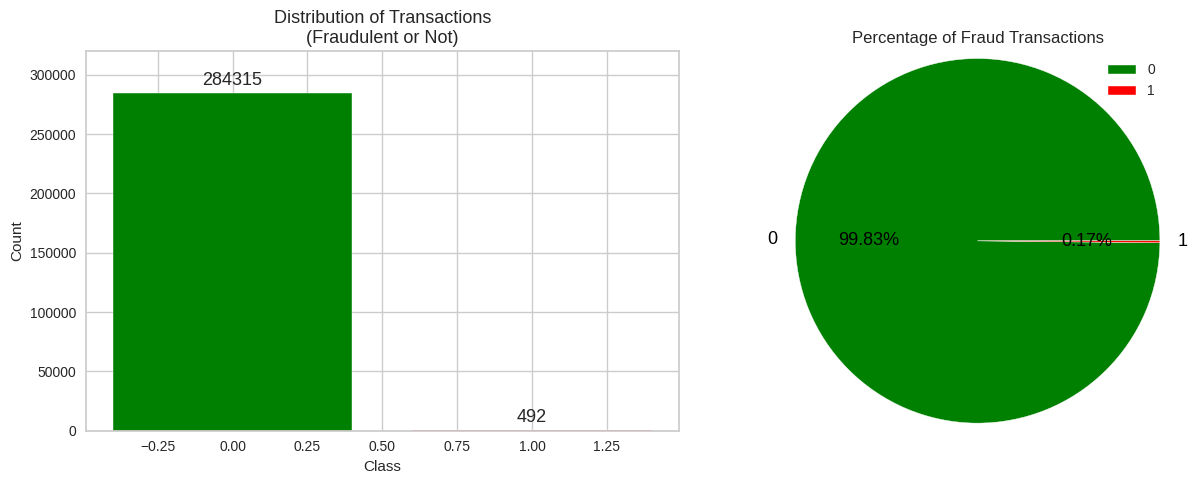

In [ ]:
plt.figure(figsize=(13,5))

x = df['Class'].value_counts().index
y = df['Class'].value_counts().values

plt.subplot(121)
g = plt.bar(x, y, label='Class', color=['green','red'])
plt.bar_label(g, padding=3, size=13), plt.ylim(0, 320000)

plt.xlabel('Class'), plt.ylabel('Count')
plt.title('Distribution of Transactions\n(Fraudulent or Not)', size=13)

plt.subplot(122)
plt.pie(y, labels=x, autopct='%0.2f%%', radius=1.2, textprops={'color':'black','fontsize': 13},
        colors=['green','red'])
plt.legend()
plt.title("Percentage of Fraud Transactions")
plt.tight_layout();

## Correlation and Skewness

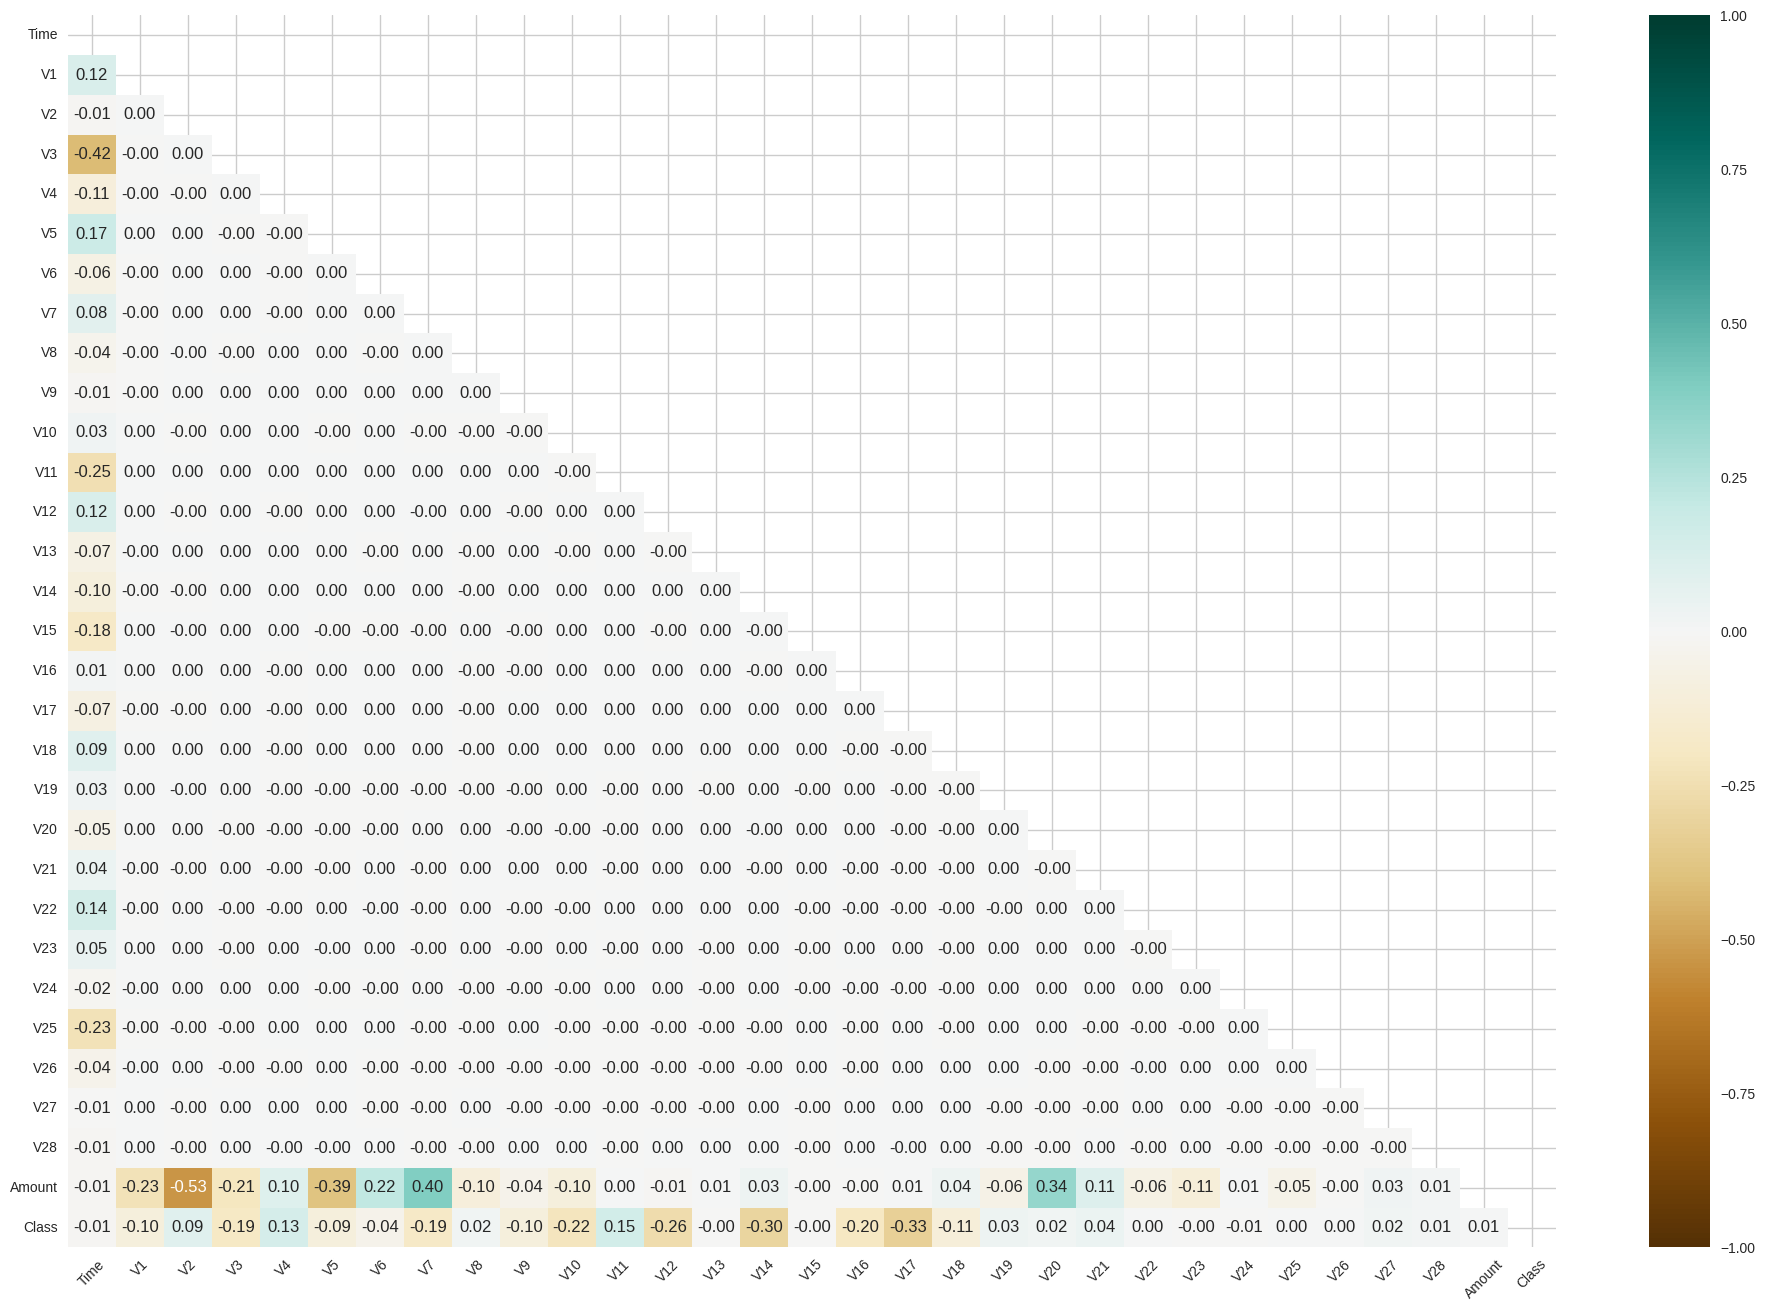

In [ ]:
matrix = np.triu(df.corr())
fig,ax = plt.subplots(figsize=(24, 16),dpi=100)
sns.heatmap (df.corr(), annot=True, ax=ax, fmt='.2f', vmin=-1, vmax=1, center=0,mask=matrix, cmap='BrBG')
plt.xticks(rotation = 45);

**What are the first insights?**

- The features (V1-V28) are the principal components (numerical input components) obtained using PCA.
   - Principal Component Analysis (PCA) is a dimensionality reduction technique commonly used in the field of machine learning and statistics. Its primary goal is to transform the original variables of a dataset into a new set of uncorrelated variables, called principal components, which capture the most significant variance in the data. By doing so, PCA can help simplify complex datasets while retaining important information.
   - Principal components are orthogonal to each other, meaning they are uncorrelated. The correlation between the features (V1-V28) is zero. This is a fundamental property of PCA, and it helps in reducing multicollinearity in the data.
   - PCA is a method that simplifies a large data set with many features for each data point. It does this by creating new indices that summarize most of the information in the original features.
- Some degree of correlation can be seen between features (V1-V28) and the Amount/Time features.

[Understanding principal component analysis and discovering underlying patterns](https://towardsdatascience.com/understand-your-data-with-principle-component-analysis-pca-and-discover-underlying-patterns-d6cadb020939)

We need to define the positive and negative correlations of features on prediction.

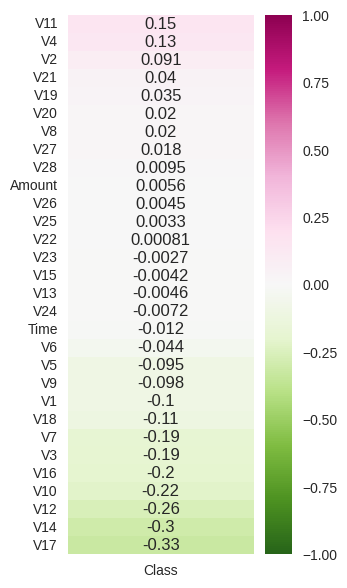

In [ ]:
plt.figure(figsize=(3,7))
sns.heatmap(data=df.corr()[["Class"]].drop("Class").sort_values(by="Class",ascending=False),
            annot=True, vmax=1,vmin=-1, cmap='PiYG_r');

### Highly Correlated Features

In [ ]:
# getting absolute values of correlation coefficients of the features
corr_matrix = df.corr()
corr_matrix_class_only= pd.DataFrame(corr_matrix['Class'])
corr_matrix_class_only["absolute_corr_val"]= corr_matrix_class_only.apply(lambda x: abs(x))

## Sorting in descending order (of absolute values of correlation coefficients)
corr_matrix_top10_class_only= corr_matrix_class_only.sort_values(by="absolute_corr_val", ascending=False)[1:11]
#print(colored(f"Top 10 feature variables related with Class:\n {list(corr_matrix_top10_class_only.index)}",attrs=['bold']) );print()

## Top 10 correlated variables with class (except Class variable)
top10_df= pd.DataFrame({"Rank": np.arange(1,11), "Top10_Feature_Variables": corr_matrix_top10_class_only.index, \
                       "Correlation_with_Class": corr_matrix_top10_class_only.Class})
top10_df.set_index("Rank", inplace=True)
top10_df

,Top10_Feature_Variables,Correlation_with_Class
Rank,,
1,V17,-0.326
2,V14,-0.303
3,V12,-0.261
4,V10,-0.217
5,V16,-0.197
6,V3,-0.193
7,V7,-0.187
8,V11,0.155
9,V4,0.133


- Some features, such as V17, V14, V12 are negatively correlated with the target class. That means that the lower these values, the more likely the transaction will be a fraudulent.
- Features V4, V11 are positively correlated. That means that the higher these values, the more likely the transaction will be a fraudulent.

In [ ]:
df.duplicated().sum()

np.int64(1081)

In [ ]:
df[df.duplicated()]["Class"].value_counts()

,count
Class,
0,1062
1,19


## Checking The Outliers

### Standard Deviation Method

In [ ]:
from collections import Counter

"""
    Takes a dataframe df of features and returns an index list corresponding to the outlier observations
     according to the Interquartile method.
    """
outlier_indices = []

for column in df.select_dtypes("number"):
        # calculate the mean and standard deviation of the data frame
        data_mean = df[column].mean()
        data_std = df[column].std()

        # calculate the cutoff value
        cut_off = data_std * 3

        # Determining a list of indices of outliers for feature column
        outlier_list_column = df[(df[column] < data_mean - cut_off) | (df[column] > data_mean + cut_off)].index

        # appending the found outlier indices for column to the list of outlier indices
        outlier_indices.extend(outlier_list_column)
        if column != 'Class':
    # selecting observations containing more than x outliers
            outlier_indices_out = Counter(outlier_indices)
            outlier= len(outlier_indices_out)

print(outlier)

37816


- This common approach defines outliers as data points that fall more than 3 standard deviations away from the mean. The multiplier of 3 can be adjusted based on the expected level of outliers in your data.
- In highly anomalous data like this, the distribution is often skewed or has extreme outliers, making the IQR less reliable. There are 37816 outliers according to the result.

### IQR Method

In [ ]:
"""
    Takes a dataframe df of features and returns an index list corresponding to the outlier observations
     according to the Interquartile method.
    """

outlier_index = []

for column in df.select_dtypes("number"):
        # calculate the mean and standard deviation of the data frame
        first_quartile = df[column].quantile(0.25)
        third_quartile = df[column].quantile(0.75)
        IQR = third_quartile - first_quartile

        # calculate the cutoff value
        u_l = IQR * 3

        # Determining a list of indices of outliers for feature column
        outlier_columns = df[(df[column] < first_quartile - u_l) | (df[column] > third_quartile + u_l)].index

        # appending the found outlier indices for column to the list of outlier indices
        outlier_index.extend(outlier_columns)
        if column != 'Class':

    # selecting observations containing more than x outliers
            outlier_index_out = Counter(outlier_index)
            outliers= len(outlier_index_out)

print(outliers)

53336


- The IQR method identifies outliers based on their deviation from the middle 50% of the data (interquartile range). In highly anomalous data like this, the distribution is often skewed or has extreme outliers, making the IQR less reliable. There are 53336 outliers according to the result.

In [ ]:
df_withoutliers = df.drop(outlier_indices_out, axis = 0).reset_index(drop=True)

In [ ]:
df_withoutliers

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,0.091,-0.552,-0.618,-0.991,-0.311,1.468,-0.470,0.208,0.026,0.404,0.251,-0.018,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0
1,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,-0.167,1.613,1.065,0.489,-0.144,0.636,0.464,-0.115,-0.183,-0.146,-0.069,-0.226,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0
2,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,-0.055,-0.226,0.178,0.508,-0.288,-0.631,-1.060,-0.684,1.966,-1.233,-0.208,-0.108,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0
3,2.000,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,0.753,-0.823,0.538,1.346,-1.120,0.175,-0.451,-0.237,-0.038,0.803,0.409,-0.009,0.798,-0.137,0.141,-0.206,0.502,0.219,0.215,69.990,0
4,2.000,-0.426,0.961,1.141,-0.168,0.421,-0.030,0.476,0.260,-0.569,-0.371,1.341,0.360,-0.358,-0.137,0.518,0.402,-0.058,0.069,-0.033,0.085,-0.208,-0.560,-0.026,-0.371,-0.233,0.106,0.254,0.081,3.670,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246986,172784.000,2.040,-0.175,-1.197,0.235,-0.009,-0.727,0.017,-0.118,0.435,0.268,0.523,0.559,-0.835,0.626,-0.541,0.225,-0.605,-0.163,0.562,-0.257,-0.268,-0.717,0.298,-0.360,-0.316,0.201,-0.081,-0.075,2.680,0
246987,172785.000,0.120,0.931,-0.546,-0.745,1.130,-0.236,0.813,0.115,-0.204,-0.657,0.645,0.191,-0.546,-0.732,-0.808,0.600,0.070,0.373,0.129,0.001,-0.314,-0.809,0.050,0.103,-0.436,0.124,0.218,0.069,2.690,0
246988,172787.000,-0.733,-0.055,2.035,-0.739,0.868,1.058,0.024,0.295,0.585,-0.976,-0.150,0.916,1.215,-0.675,1.165,-0.712,-0.026,-1.221,-1.546,0.060,0.214,0.924,0.012,-1.016,-0.607,-0.395,0.068,-0.054,24.790,0
246989,172788.000,1.920,-0.301,-3.250,-0.558,2.631,3.031,-0.297,0.708,0.432,-0.485,0.412,0.063,-0.184,-0.511,1.329,0.141,0.314,0.396,-0.577,0.001,0.232,0.578,-0.038,0.640,0.266,-0.087,0.004,-0.027,67.880,0


- Outliers can distort measures like mean, median, standard deviation or IQR, giving a misleading impression of the central tendency or spread of the data.
- These methods might misclassify regular data points as outliers, leading to incorrect data cleaning or inaccurate analysis.

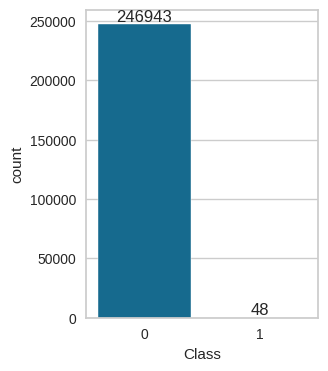

In [ ]:
plt.figure(figsize=(3,4))
ax = sns.countplot(x='Class',data=df_withoutliers)
for i in ax.containers:
    ax.bar_label(i,)

We have only 48 fraud transactions in entire data frame. We deleted most of fraud transactions from a dataframe so it will be hard to get insight the remaining part of it. Because we have very skewed data so outliers methods like IQR or standard deviation don't work. We have option to drop the values that fall more than a defined limit for example the amounts more than 10.000. But we had better go on without dropping the outliers.

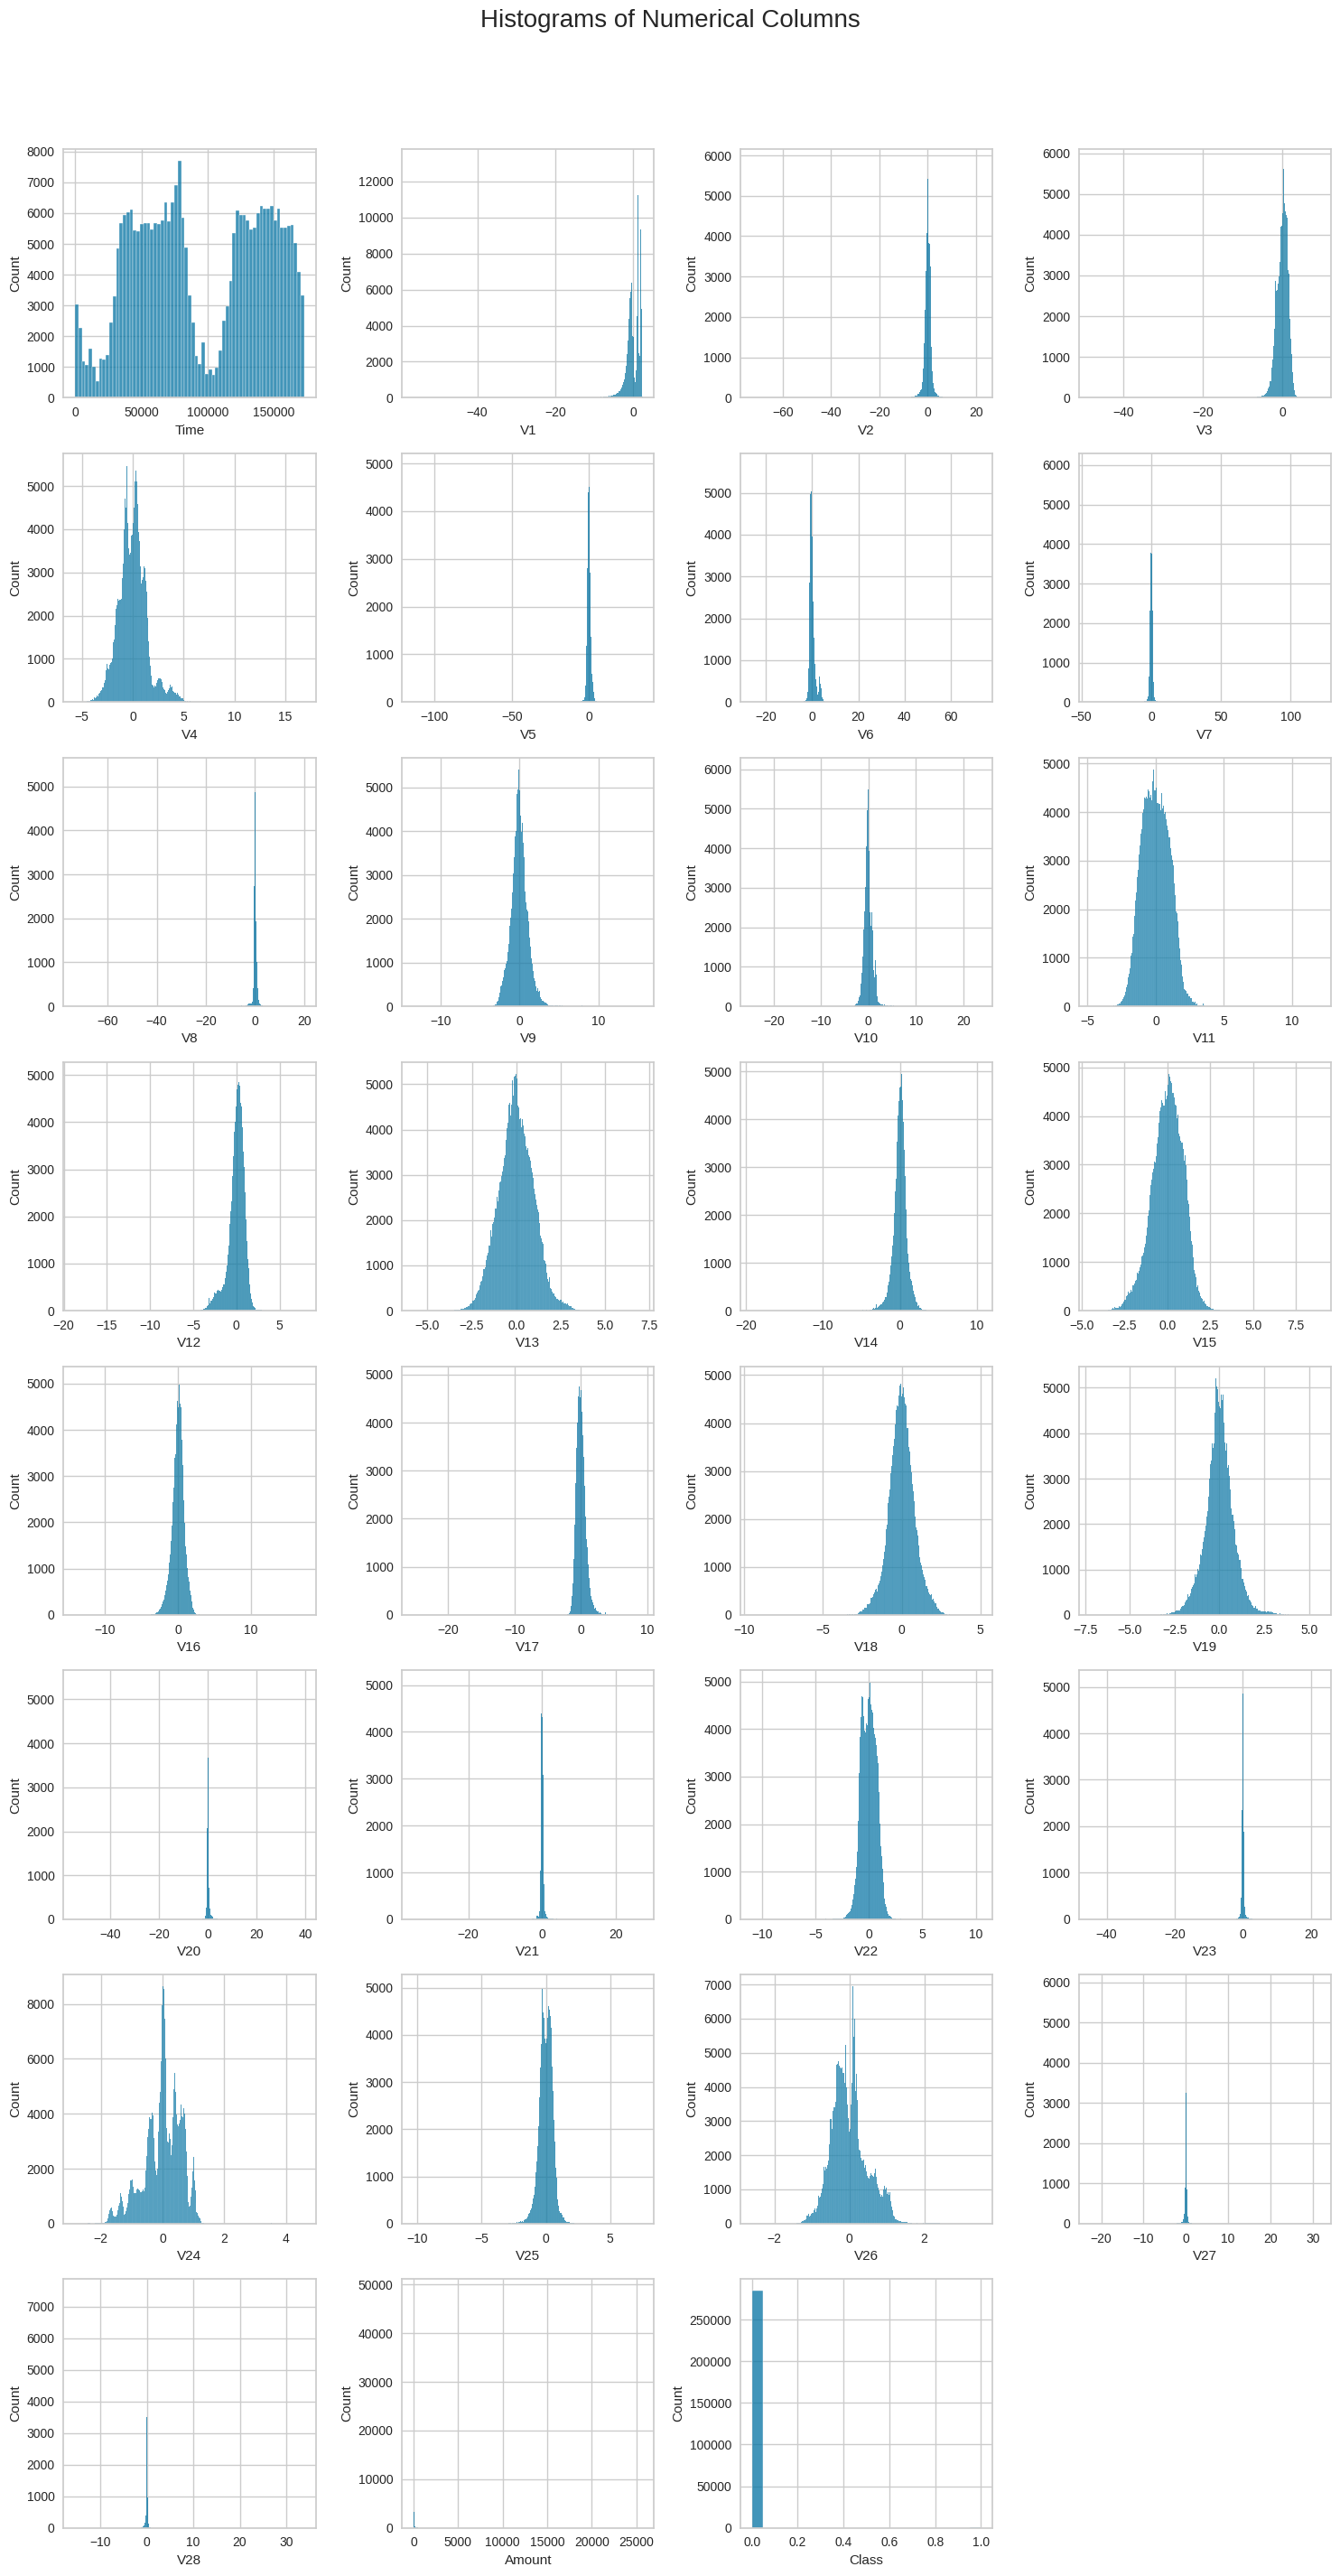

In [ ]:
## Histograms
fig = plt.figure(figsize=(15, 30))
plt.suptitle('Histograms of Numerical Columns', fontsize=20)
for i in range(df.shape[1]):
    plt.subplot(8, 4, i+1)
    f = plt.gca()
    #f.set_title(df.columns.values[i])
    sns.histplot(df.iloc[:, i])

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) #plt.tight_layout(pad=2)

- The features (V1-V28) are **components** because;
  -  Standardization rescales each feature to have zero mean and unit standard deviation. This is also called Z-score normalization.  Standardization is important for PCA because it ensures that each feature contributes equally to the variance of the data, regardless of its scale,
  -  There is no correlation between them,
  - There is no missing value, because PCA requires a complete data matrix, where every row (observation) has a value for every column (variable). If some values are missing, PCA cannot be directly applied.

## Time

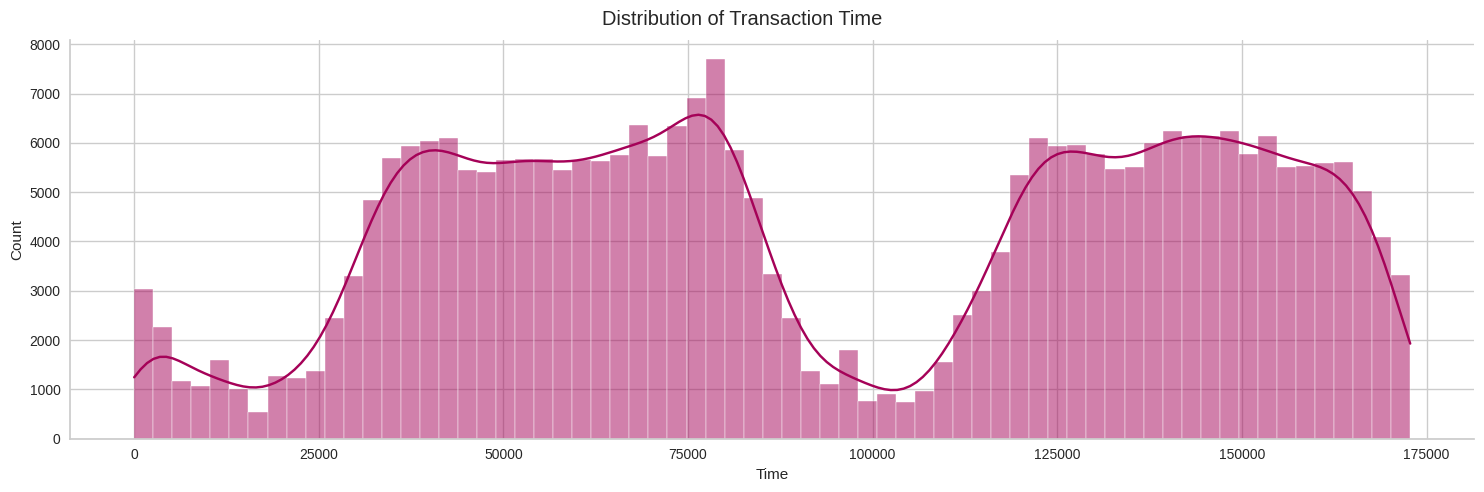

In [ ]:
dist = sns.displot(data=df, x="Time", kde=True,  color='m', height=5, aspect=3)
dist.fig.subplots_adjust(top=0.92)
dist.fig.suptitle('Distribution of Transaction Time');

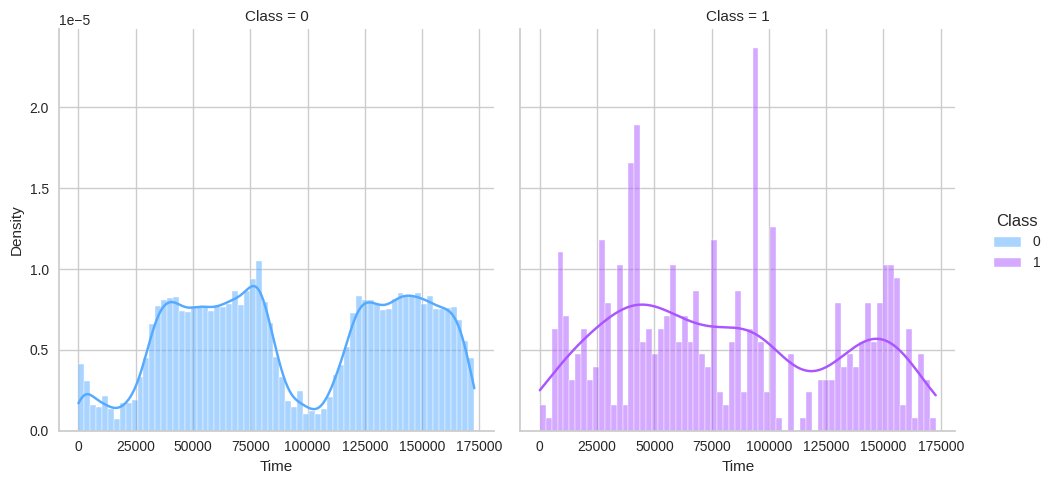

In [ ]:
sns.displot(df, x="Time", col="Class", hue= "Class",  kde=True, stat="density", common_norm=False, palette="cool");

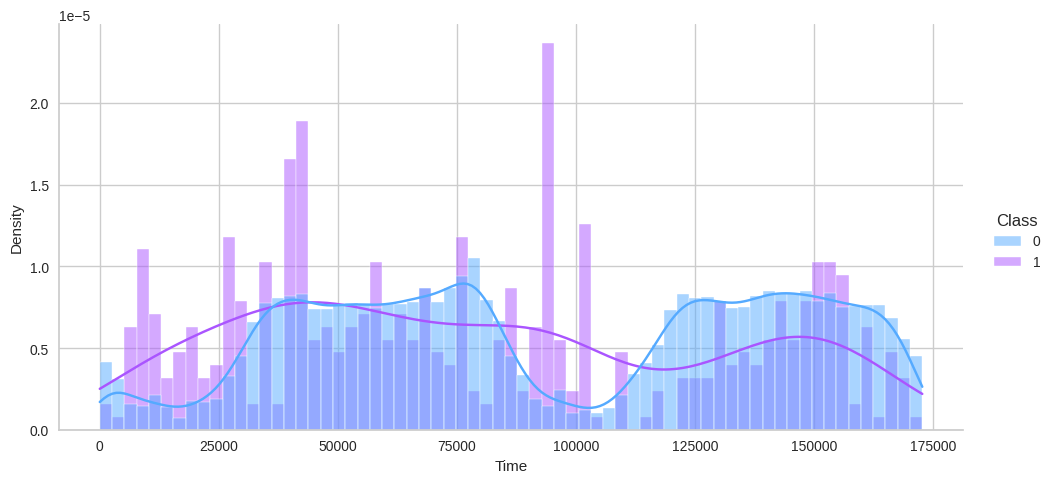

In [ ]:
sns.displot(df, x="Time", hue= "Class", kde=True, stat="density",common_norm=False, palette="cool", height=5, aspect=2);

- A visual representation of transaction frequencies over time illustrates an overlapping pattern between fraudulent and legitimate transactions

Fraudulent transactions are more uniformly distributed in time than valid transactions - they occur equally at any time of the day, even during the night in Europe timezone when real transactions are low.

KDE plots are a way of **estimating the probability density** function of a variable based on a sample of data. Different libraries or functions may use **different methods to calculate the KDE, such as the bandwidth, the kernel function, or the binning algorithm**. These methods affect how smooth or jagged the KDE curve looks, and how well it matches the true distribution of the data.

According to the web search results, one possible reason why the KDE plots look different in sns distplot and plotly distplot is that they use different rules to determine the bandwidth, which is the width of the Gaussian kernel around each data point. **Sns distplot uses the Freedman-Diaconis rule** by default, which depends on the interquartile range and the number of data points. **Plotly distplot uses Scott’s rule** by default, which depends on the standard deviation and the number of data points. These rules may give different bandwidth values for the same data, resulting in different shapes of the KDE curve.

In [ ]:
'''plotting large datasets with Plotly in Colab can sometimes lead to performance issues
or rendering failures. Here's we downsized the data.'''
sampled_df = df.sample(frac=0.4, random_state=42)
fig = px.histogram(sampled_df, x="Time", color="Class", histnorm='probability', marginal="box", hover_data=sampled_df.columns)
fig.show()

**Do fraudulent transactions occur more often during certain time frame ?**

In [ ]:
df['hour']=df['Time'].apply(lambda x: np.floor(x / 3600))

In [ ]:
fraud_h = df[df["Class"]==1]['hour']
non_fraud_h = df[df["Class"]==0]['hour']
dist_data = [non_fraud_h, fraud_h]
group_labels = ['Non-Fraud', 'Fraud']

In [ ]:
fig = px.histogram(df, x="hour", color="Class", histnorm='probability', color_discrete_sequence=["slategray", "magenta"])
fig.update_layout(title='Transactions Hour Density Plot')
fig.show()

In [ ]:
fig = go.Figure()
fig.add_trace(go.Histogram(histfunc="count", y=df.Amount, x=fraud_h, name="count"))
fig.add_trace(go.Histogram(histfunc="avg", y=df.Amount, x=fraud_h, name="avg"))

fig.show()

When examining the graph, we observe that the counts of fraudulent transactions and the average amounts of these transactions display variability. While a few transactions may have high average amounts, the overall average across numerous transactions can be low. Unfortunately, time/hour does not provide us with any conclusive inference. So we will drop **"Time"** and **"hour"** features in **Data Cleaning** part.

## Amount

In [ ]:
fraud_results = []

for hour in range(0,48):  # Assuming hours range from 1 to 48
    result = df[(df["hour"] == hour) & (df["Class"] == 1)].groupby("hour").agg(
        transaction=("Amount", "count"),
        total_amount=("Amount", "sum"),
        average_amount=("Amount", "mean"))
    fraud_results.append(result)

fraud_result = pd.concat(fraud_results).sort_values(by="average_amount", ascending=False)

fraud_result

,transaction,total_amount,average_amount
hour,,,
36.000,8,3181.650,397.706
34.000,6,2225.600,370.933
24.000,4,1291.070,322.767
0.000,2,529.000,264.500
19.000,7,1802.190,257.456
17.000,12,2916.380,243.032
46.000,6,1433.230,238.872
38.000,10,2236.250,223.625
40.000,8,1770.810,221.351


In [ ]:
fraud = df[df["Class"]==1]
non_fraud = df[df["Class"]==0]

In [ ]:
fraud["Amount"].describe([0.1,0.25,0.5,0.75,0.9,0.95,0.99,1])

,Amount
count,492.000
mean,122.211
std,256.683
min,0.000
10%,0.760
25%,1.000
50%,9.250
75%,105.890
90%,346.746
95%,640.905


- A transaction with an amount of 0 seems likely to be fraudulent; however, scammers may obtain the card's confidential details from insecure websites. If there is an additional identity verification process, the transaction may appear as amount = 0.
- Nearly ten fraud transactions exceed 1000€

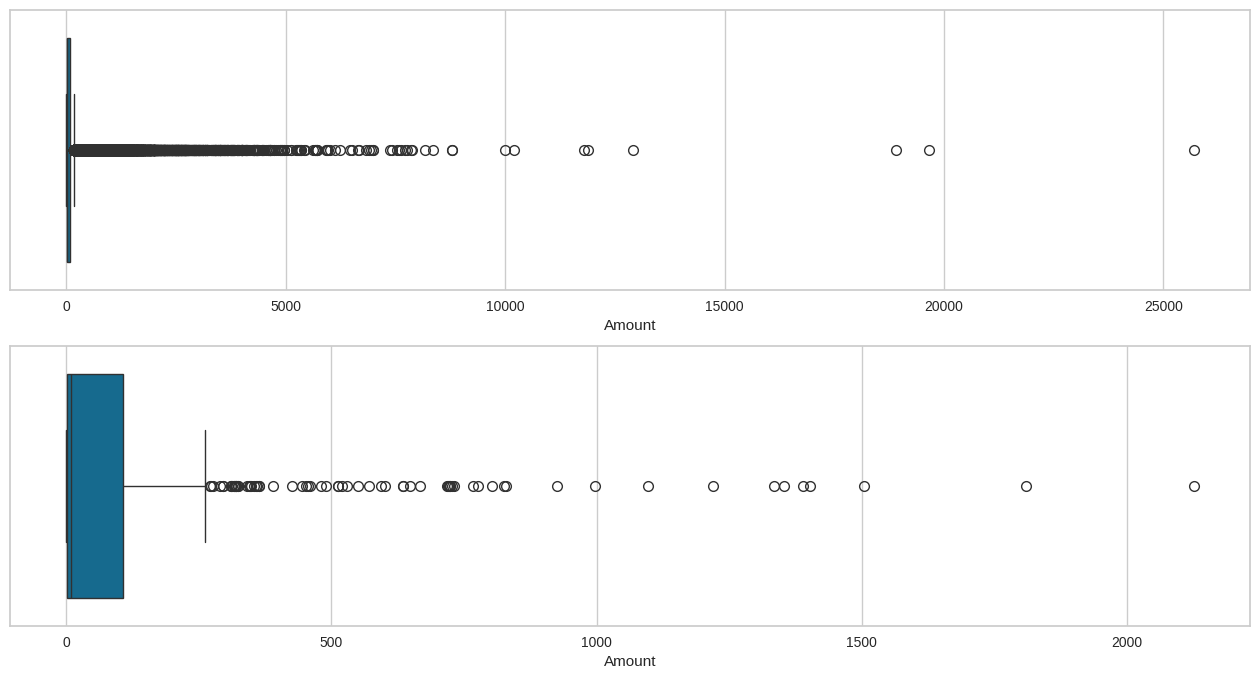

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(16,8))
sns.boxplot(x=df[df['Class'] == 0].Amount, ax=ax[0])
sns.boxplot(x=df[df['Class'] == 1].Amount, ax=ax[1])
plt.show()

## Features by PCA

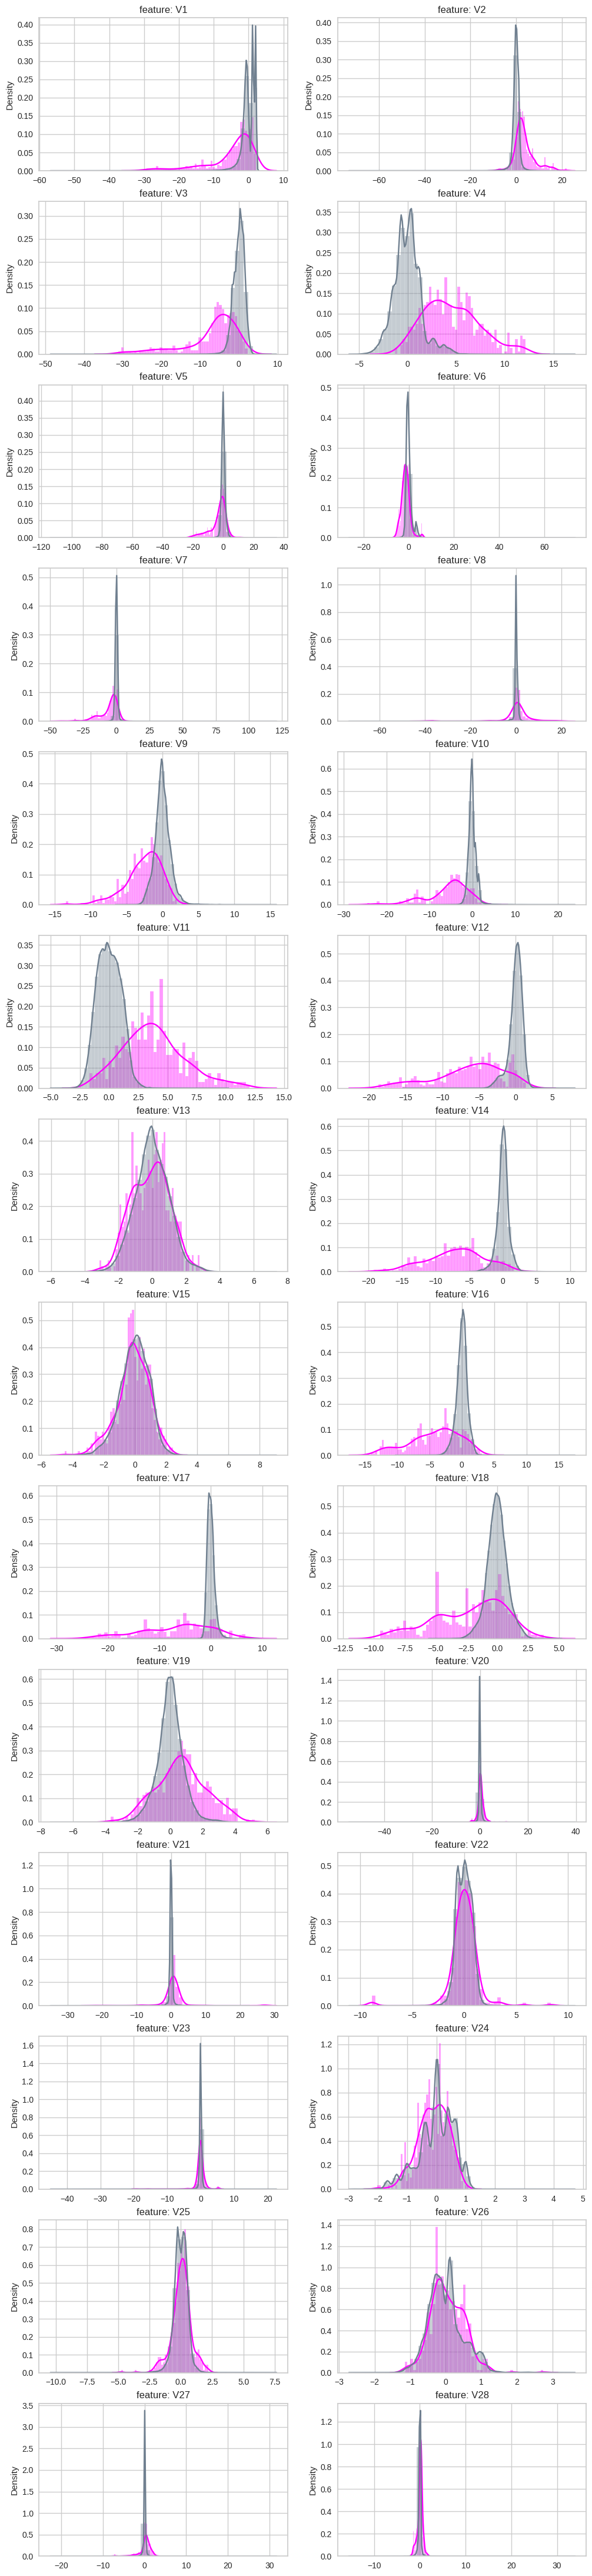

In [ ]:
plt.figure(figsize=(12,14*4))
gs = gridspec.GridSpec(14, 2)
for i, cn in enumerate(df[df.iloc[:, 1:29].columns]):
    ax = plt.subplot(gs[i])
    sns.distplot(df[cn][df.Class == 1], bins=50,color="Magenta")
    sns.distplot(df[cn][df.Class == 0], bins=50,color="Slategrey")
    ax.set_xlabel('')
    ax.set_title('feature: ' + str(cn))
plt.show()

- In some features, there is minimal overlap between the two classes. These features might be better discriminators. So by feature engineering, we can take these features and drop the others.

## Data Cleaning

We will drop the Time/Hour and bad discriminator features.   

In [ ]:
df_n  = df.drop(['V1','V8','V13','V15','V20','V21','V22','V23','V24',"V19","V6",
                      'V25','V26','V27','V28',"Time","hour"], axis =1)

In [ ]:
df_n

,V2,V3,V4,V5,V7,V9,V10,V11,V12,V14,V16,V17,V18,Amount,Class
0,-0.073,2.536,1.378,-0.338,0.240,0.364,0.091,-0.552,-0.618,-0.311,-0.470,0.208,0.026,149.620,0
1,0.266,0.166,0.448,0.060,-0.079,-0.255,-0.167,1.613,1.065,-0.144,0.464,-0.115,-0.183,2.690,0
2,-1.340,1.773,0.380,-0.503,0.791,-1.515,0.208,0.625,0.066,-0.166,-2.890,1.110,-0.121,378.660,0
3,-0.185,1.793,-0.863,-0.010,0.238,-1.387,-0.055,-0.226,0.178,-0.288,-1.060,-0.684,1.966,123.500,0
4,0.878,1.549,0.403,-0.407,0.593,0.818,0.753,-0.823,0.538,-1.120,-0.451,-0.237,-0.038,69.990,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,10.072,-9.835,-2.067,-5.364,-4.918,1.914,4.356,-1.593,2.712,4.627,1.108,1.992,0.511,0.770,0
284803,-0.055,2.035,-0.739,0.868,0.024,0.585,-0.976,-0.150,0.916,-0.675,-0.712,-0.026,-1.221,24.790,0
284804,-0.301,-3.250,-0.558,2.631,-0.297,0.432,-0.485,0.412,0.063,-0.511,0.141,0.314,0.396,67.880,0
284805,0.530,0.703,0.690,-0.378,-0.686,0.392,-0.399,-1.934,-0.963,0.450,-0.609,0.510,1.114,10.000,0


# 2.Train-Test-Split

In [ ]:
X = df_n.drop('Class', axis=1)
y = df_n['Class']

In [ ]:
X_train, X_test, y_train,y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
X_train

,V2,V3,V4,V5,V7,V9,V10,V11,V12,V14,V16,V17,V18,Amount
265518,-0.753,-1.355,-0.662,1.503,-1.480,1.407,-0.157,-0.114,0.510,-0.067,0.353,-0.766,0.142,7.320
180305,-0.049,-3.059,0.248,2.943,-0.002,0.046,0.285,-0.255,0.326,0.721,-0.754,-0.271,-0.696,2.990
42664,0.603,0.712,-0.992,-0.826,-2.213,0.001,-2.010,-0.387,1.820,0.123,1.123,-0.725,0.147,175.100
198723,-1.500,-0.748,-1.668,-1.394,-1.428,-1.118,1.756,0.093,-0.722,-0.195,-0.066,0.073,0.768,6.100
82325,-1.011,0.116,-3.455,0.716,0.504,-0.045,-0.559,-0.251,-0.055,0.135,-2.096,-0.400,1.598,86.100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233802,-0.517,-0.620,0.130,-0.285,-0.822,0.996,0.213,0.320,0.584,0.062,0.684,-0.906,0.739,5.990
85418,0.658,1.582,-0.024,0.585,0.609,0.453,0.109,0.522,0.373,-0.402,-1.880,1.242,-2.623,36.990
29062,0.072,0.497,1.505,-0.380,0.101,0.320,-0.132,-0.306,0.445,0.167,-0.797,0.405,-1.033,45.420
13766,0.301,0.333,0.513,0.065,-0.146,1.111,-0.269,1.709,-1.666,1.800,0.706,-0.248,0.483,0.890


[Train-Test Validation Suite Quickstart](https://docs.deepchecks.com/stable/user-guide/tabular/auto_quickstarts/plot_quick_train_test_validation.html)

In [ ]:
from deepchecks.tabular import Dataset

cat_cols = []

In [ ]:
train_ds = Dataset(X_train, label=y_train, cat_features=cat_cols)
test_ds = Dataset(X_test, label=y_test, cat_features=cat_cols)

In [ ]:
from deepchecks.tabular.suites import train_test_validation

validation_suite = train_test_validation()
suite_result = validation_suite.run(train_ds, test_ds)
suite_result

<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Train Test Validation Suite

Dropping **V12, V16, V17,** and **V18** simply because they show a Predictive Power Score (PPS) difference between train and test splits is a risky move. In credit card fraud detection, these components (**especially V17 and V12**) are your most powerful discriminators. Completely removing them would significantly degrade your models' overall Recall.

**PPS for classification = PPS = (F1_model - F1_naive) / (1 - F1_naive)**

1. For a PCA dataset, we have no so many options for feature engineering. For this one, I used **test rate as 0.3** and it gave better results for Train-Test features' Predictive Power Score(pps) difference.
2. The other option may be defining on our **check a condition**. The check has 2 possible built-in conditions
- **add_condition_feature_pps_difference_not_greater_than** - Validate that the difference in the PPS between train and test is not larger than defined amount (default 0.2)
- **add_condition_feature_pps_in_train_not_greater_than** - Validate that the PPS scores on train dataset are not exceeding a defined amount (default 0.7)
by this method we can change thresholds.

[Feature Label Correlation Change/Define a condition](https://docs.deepchecks.com/stable/tabular/auto_checks/train_test_validation/plot_feature_label_correlation_change.html#sphx-glr-tabular-auto-checks-train-test-validation-plot-feature-label-correlation-change-py)

- If the task is a classification, we compute the **weighted F1 score (wF1)** as the underlying evaluation metric (F1_model). The F1 score can be interpreted as a weighted average of the precision and recall, where an F1 score reaches its best value at 1 and worst score at 0. The relative contribution of precision and recall to the F1 score are equal. The weighted F1 takes into account the precision and recall of all classes weighted by their support. As a **baseline score (F1_naive)**, we calculate the weighted F1 score for a model that always predicts the most common class of the target column (F1_most_common) and a model that predicts random values (F1_random). **F1_naive is set to the maximum of F1_most_common and F1_random**. The F1 naive score is a baseline score used to normalize the Predictive Power Score which is never smaller than 0.

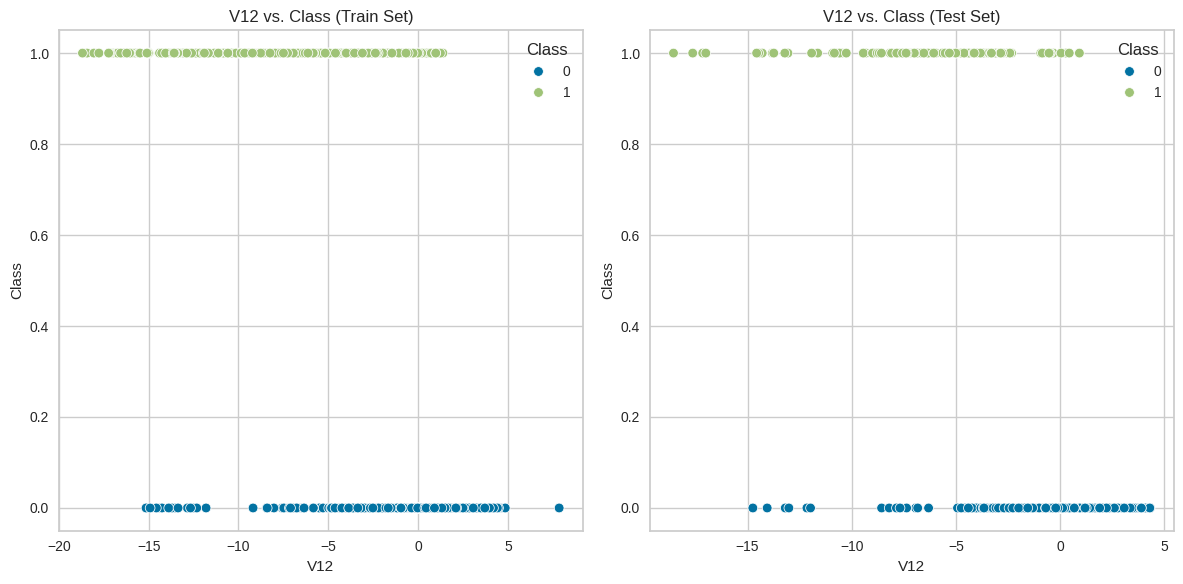

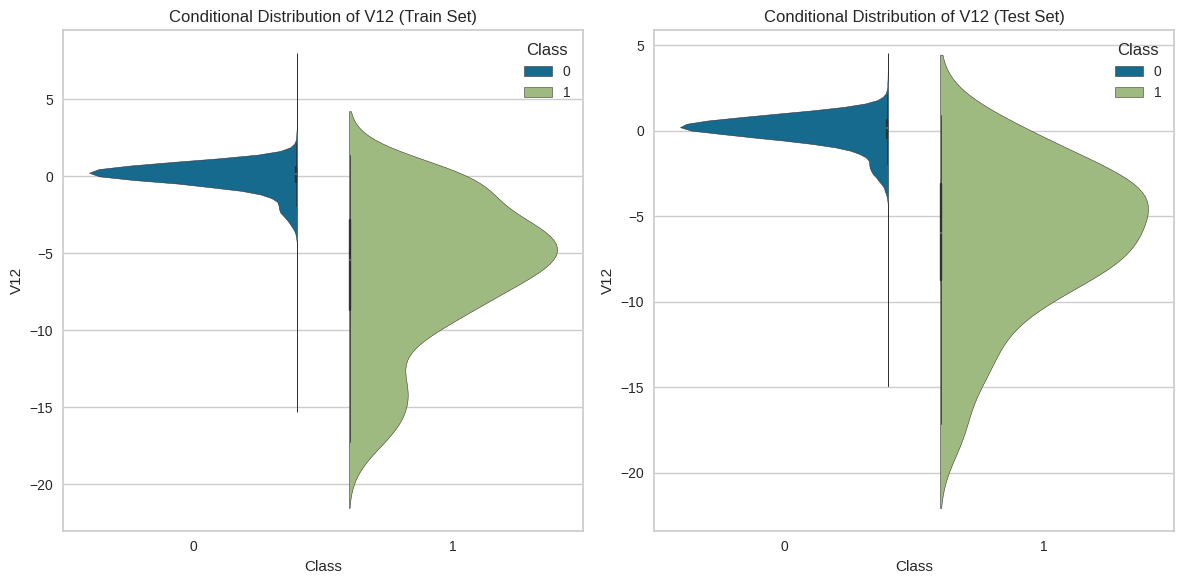

In [ ]:
# Scatter plots for train and test sets
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x='V12', y='Class', data=pd.concat([X_train, y_train.rename('Class')], axis=1), hue='Class')
plt.title('V12 vs. Class (Train Set)')

plt.subplot(1, 2, 2)
sns.scatterplot(x='V12', y='Class', data=pd.concat([X_test, y_test.rename('Class')], axis=1), hue='Class')
plt.title('V12 vs. Class (Test Set)')

plt.tight_layout()
plt.show()

# Conditional distributions for train and test sets
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.violinplot(x='Class', y='V12', data=pd.concat([X_train, y_train], axis=1), hue='Class', split=True)
plt.title('Conditional Distribution of V12 (Train Set)')

plt.subplot(1, 2, 2)
sns.violinplot(x='Class', y='V12', data=pd.concat([X_test, y_test], axis=1), hue='Class', split=True)
plt.title('Conditional Distribution of V12 (Test Set)')

plt.tight_layout()
plt.show()

## Scaling

In [ ]:
rob_scaler = RobustScaler()

X_train['Amount'] = rob_scaler.fit_transform(X_train[['Amount']])
X_test['Amount'] = rob_scaler.transform(X_test[['Amount']])

In [ ]:
import joblib
import os

# Define the target directory path on Google Drive
save_directory = '/content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/'

# Ensure the directory exists
os.makedirs(save_directory, exist_ok=True)

# Create a dictionary to hold all splits
dataset_splits = {
    'X_train': X_train,
    'X_test': X_test,
    'y_train': y_train,
    'y_test': y_test
}

# Save the preprocessed datasets as a single joblib file for convenience
save_path = os.path.join(save_directory, 'preprocessed_data_splits.joblib')
joblib.dump(dataset_splits, save_path)
print(f"Preprocessed dataset splits successfully saved to: {save_path}")

# Example of how you will load these in your next notebook:
# import joblib
# data = joblib.load('/content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/preprocessed_data_splits.joblib')
# X_train, X_test, y_train, y_test = data['X_train'], data['X_test'], data['y_train'], data['y_test']

Preprocessed dataset splits successfully saved to: /content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/preprocessed_data_splits.joblib


### Phase 1: EDA & Preprocessing Phase Summary

#### 1. Exploratory Data Analysis & Data Cleaning
* **No Missing Values:** Checked the entire dataset containing 284,807 transactions and found zero missing entries.
* **Feature Analysis (PCA):** Features `V1` to `V28` represent principal components from PCA. As expected, they have no linear correlation with one another. However, we analyzed their distribution with respect to target class `Class`.
* **Feature Elimination:** Based on poor class discriminative power observed via KDE distributions, we removed irrelevant columns: `V1`, `V8`, `V13`, `V15`, `V20`, `V21`, `V22`, `V23`, `V24`, `V19`, `V6`, `V25`, `V26`, `V27`, `V28` along with `Time` and the engineered `hour` feature.
* **Duplicate Handling:** Identified and removed 1,081 duplicate transactions to avoid artificial model bias.
* **Outlier Strategy:** Statistical outlier detection via Standard Deviation and IQR identified many extreme observations (up to ~53k). However, since credit card fraud features are inherently heavily skewed and outliers represent critical fraud patterns, we chose not to drop these observations to prevent loss of minority class representations.

#### 2. Data Preprocessing
* **Train-Test Split:** Conducted a stratified train-test split (80/20) to preserve the original extremely imbalanced class ratio (0.172% fraud).
* **Feature Scaling:** Applied `RobustScaler` to the highly variable `'Amount'` column using statistics computed strictly from the training set, avoiding any data leakage into the test set.

---

### Transition to Separate Modeling Notebooks
To seamlessly train and test your individual models (Logistic Regression, Random Forest, XGBoost, and Artificial Neural Networks) in separate notebooks, we must serialize and save the processed splits.

#### Essential Next Steps & Best Practices Before Modeling:
1. **Maintain Random States:** Always set a fixed `random_state` (e.g., `42`) when utilizing any randomized sampler (like SMOTE, UnderSampler) or classifier initialization in your other notebooks to guarantee reproducible results.
2. **Avoid Leakage on Resampling:** When utilizing oversampling/undersampling techniques (e.g. SMOTE), **only apply them to the training set (`X_train`, `y_train`)**. Never resample your test set (`X_test`, `y_test`), as it must remain untouched to serve as a realistic proxy for real-world unseen data.